In [ ]:
from pathlib import Path
import pyreadstat

file_path = Path("../data/DEMO_L.xpt")
if not file_path.exists():
    file_path = Path("data/DEMO_L.xpt")

df, metadata = pyreadstat.read_xport(str(file_path),encoding="WINDOWS-1252")

print("Rows and columns:", df.shape)
display(df.head())

In [ ]:
print("Rows, columns:", df.shape)

print("\nColumn types:")
display(df.dtypes)

print("\nMissing values in each column:")
display(df.isna().sum().sort_values(ascending=False))

In [8]:
from pathlib import Path
import pandas as pd

file_path = Path("../data/processed/DEMO_L.csv")
df = pd.read_csv(file_path)

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (11933, 27)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60


In [9]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/processed")

for file_path in sorted(data_dir.glob("*.csv")):
    data = pd.read_csv(file_path)
    print(f"{file_path.name}: {data.shape[0]:,} rows × {data.shape[1]} columns")

ALB_CR_L.csv: 8,493 rows × 8 columns
BIOPRO_L.csv: 7,199 rows × 42 columns
BMX_L.csv: 8,860 rows × 22 columns
BPQ_L.csv: 8,501 rows × 6 columns
BPXO_L.csv: 7,801 rows × 12 columns
DEMO_L.csv: 11,933 rows × 27 columns
DIQ_L.csv: 11,744 rows × 9 columns
DSQIDS_L.csv: 11,375 rows × 45 columns
DSQTOT_L.csv: 8,860 rows × 40 columns
KIQ_U_L.csv: 7,809 rows × 9 columns


In [10]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/processed")
files = ["DEMO_L", "ALB_CR_L", "BIOPRO_L", "DSQIDS_L"]

for name in files:
    df = pd.read_csv(data_dir / f"{name}.csv", usecols=["SEQN"])
    repeated_people = (df["SEQN"].value_counts() > 1).sum()

    print(
        f"{name}: {len(df):,} rows, "
        f"{df['SEQN'].nunique():,} unique people, "
        f"{repeated_people:,} people with multiple rows"
    )

DEMO_L: 11,933 rows, 11,933 unique people, 0 people with multiple rows
ALB_CR_L: 8,493 rows, 8,493 unique people, 0 people with multiple rows
BIOPRO_L: 7,199 rows, 7,199 unique people, 0 people with multiple rows
DSQIDS_L: 11,375 rows, 4,017 unique people, 2,506 people with multiple rows


In [11]:
import json
from pathlib import Path

labels_path = Path("../data/processed/labels/DSQIDS_L_labels.json")

with labels_path.open(encoding="utf-8") as f:
    labels = json.load(f)

for column, description in labels.items():
    print(f"{column}: {description}")

SEQN: Respondent sequence number
WTDRD1: Dietary day one sample weight
DSDPID: Supplement ID Number
DSDSUPP: Supplement Name
DSDANTA: Antacid reported as a dietary supplement
DSD070: Was container seen?
DSDMTCH: Matching code
DSD103: Days supplement taken, past 30 days
DSD122Q: Quantity of supplement taken daily
DSD122U: Dosage form
DSDACTSS: Reported serving size/label serving size
DSQIKCAL: Energy (kcal)
DSQIPROT: Protein (gm)
DSQICARB: Carbohydrate (gm)
DSQISUGR: Total sugars (gm)
DSQIFIBE: Dietary fiber (gm)
DSQITFAT: Total fat (gm)
DSQISFAT: Total saturated fatty acids (gm)
DSQIMFAT: Total monounsaturated fatty acids (gm)
DSQIPFAT: Total polyunsaturated fatty acids (gm)
DSQICHOL: Cholesterol (mg)
DSQILYCO: Lycopene (mcg)
DSQILZ: Lutein + zeaxanthin (mcg)
DSQIVB1: Thiamin (Vitamin B1) (mg)
DSQIVB2: Riboflavin (Vitamin B2) (mg)
DSQINIAC: Niacin (mg)
DSQIVB6: Vitamin B6 (mg)
DSQIFA: Folic acid (mcg)
DSQIFDFE: Folate, DFE (mcg)
DSQICHL: Total choline (mg)
DSQIVB12: Vitamin B12 (mcg)
D

In [12]:
from pathlib import Path
import pandas as pd

file_path = Path("../data/processed/DSQIDS_L.csv")

dsq = pd.read_csv(
    file_path,
    usecols=["SEQN", "DSDPID", "DSDSUPP", "DSDMTCH", "DSD103", "DSD122Q", "DSD122U"]
)

mask = dsq["DSDSUPP"].astype("string").str.contains(
    "creatin", case=False, na=False
)

creatine_rows = dsq.loc[mask].copy()

print("Matching supplement records:", len(creatine_rows))
print("Unique participants:", creatine_rows["SEQN"].nunique())
print("Unique product names:", creatine_rows["DSDSUPP"].nunique())

display(
    creatine_rows[
        ["SEQN", "DSDPID", "DSDSUPP", "DSDMTCH", "DSD103", "DSD122Q", "DSD122U"]
    ].drop_duplicates()
)

Matching supplement records: 24
Unique participants: 24
Unique product names: 16


,SEQN,DSDPID,DSDSUPP,DSDMTCH,DSD103,DSD122Q,DSD122U
447,130904.0,25409.0,NUTRICOST PERFORMANCE CREATINE MONOHYDRATE MIC...,1.0,30.0,1.0,21.0
918,131353.0,2788.0,DEFAULT CREATINE MONOHYDRATE,5.0,3.0,1.0,12.0
1371,131827.0,2788.0,DEFAULT CREATINE MONOHYDRATE,5.0,5.0,1.0,12.0
1625,132127.0,26006.0,GNC PRO PERFORMANCE CREATINE MONOHYDRATE 5000M...,1.0,30.0,1.0,21.0
1998,132416.0,20403.0,ON OPTIMUM NUTRITION MICRONIZED CREATINE POWDE...,1.0,30.0,1.0,12.0
2130,132553.0,2788.0,DEFAULT CREATINE MONOHYDRATE,5.0,30.0,1.0,12.0
2880,133320.0,2578.0,CREATINE MONOHYDRATE 5 G,3.0,30.0,1.0,12.0
3538,134053.0,10009.0,DEFAULT CREATINE CAPSULES,5.0,30.0,1.0,1.0
4137,134708.0,2788.0,DEFAULT CREATINE MONOHYDRATE,5.0,20.0,1.0,12.0
4611,135201.0,3728.0,CREATINE MONOHYDRATE 750 MG,3.0,14.0,1.0,1.0


In [13]:
print(
    creatine_rows.groupby("DSDMTCH")
    .agg(
        supplement_records=("SEQN", "size"),
        unique_people=("SEQN", "nunique")
    )
    .sort_index()
)

         supplement_records  unique_people
DSDMTCH                                   
1.0                      16             16
3.0                       2              2
5.0                       6              6


In [14]:
from pathlib import Path
import pandas as pd

demo = pd.read_csv(
    Path("../data/processed/DEMO_L.csv"),
    usecols=["SEQN", "RIDAGEYR"]
)

strict_ids = set(
    creatine_rows.loc[creatine_rows["DSDMTCH"] == 1, "SEQN"]
)

broad_ids = set(
    creatine_rows.loc[creatine_rows["DSDMTCH"].isin([1, 2, 3, 4, 5]), "SEQN"]
)

demo["strict_creatine"] = demo["SEQN"].isin(strict_ids)
demo["broad_creatine"] = demo["SEQN"].isin(broad_ids)

adults = demo[demo["RIDAGEYR"] >= 20]

print("Adults in the full dataset:", len(adults))
print("Strict creatine group, adults:", adults["strict_creatine"].sum())
print("Broad creatine group, adults:", adults["broad_creatine"].sum())

Adults in the full dataset: 7809
Strict creatine group, adults: 15
Broad creatine group, adults: 22


In [15]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/processed")

demo = pd.read_csv(
    data_dir / "DEMO_L.csv",
    usecols=["SEQN", "RIDAGEYR"]
)

alb = pd.read_csv(
    data_dir / "ALB_CR_L.csv",
    usecols=["SEQN", "URDACT"]
)

biopro = pd.read_csv(
    data_dir / "BIOPRO_L.csv",
    usecols=["SEQN", "LBXSCR"]
)

adults = demo[demo["RIDAGEYR"] >= 20].copy()

adult_kidney = (
    adults
    .merge(alb, on="SEQN", how="left", validate="one_to_one")
    .merge(biopro, on="SEQN", how="left", validate="one_to_one")
)

adult_kidney["strict_creatine"] = adult_kidney["SEQN"].isin(strict_ids)
adult_kidney["broad_creatine"] = adult_kidney["SEQN"].isin(broad_ids)

groups = {
    "All adults": pd.Series(True, index=adult_kidney.index),
    "Strict creatine": adult_kidney["strict_creatine"],
    "Broad-only creatine": (
        adult_kidney["broad_creatine"] & ~adult_kidney["strict_creatine"]
    ),
    "No name-identified creatine": ~adult_kidney["broad_creatine"],
}

summary = pd.DataFrame([
    {
        "group": name,
        "people": int(mask.sum()),
        "with_urine_ACR": int(adult_kidney.loc[mask, "URDACT"].notna().sum()),
        "with_serum_creatinine": int(adult_kidney.loc[mask, "LBXSCR"].notna().sum()),
    }
    for name, mask in groups.items()
])

display(summary)

,group,people,with_urine_ACR,with_serum_creatinine
0,All adults,7809,5910,5443
1,Strict creatine,15,15,13
2,Broad-only creatine,7,7,7
3,No name-identified creatine,7787,5888,5423


In [16]:
comparison = adult_kidney.copy()

comparison["group"] = comparison["broad_creatine"].map({
    True: "Creatine name found",
    False: "No creatine name found",
})

rows = []

for group_name, group_data in comparison.groupby("group"):
    for variable in ["URDACT", "LBXSCR"]:
        values = group_data[variable].dropna()

        rows.append({
            "group": group_name,
            "measure": variable,
            "n": len(values),
            "median": values.median(),
            "Q1": values.quantile(0.25),
            "Q3": values.quantile(0.75),
            "mean": values.mean(),
        })

display(pd.DataFrame(rows).round(2))

,group,measure,n,median,Q1,Q3,mean
0,Creatine name found,URDACT,22,4.62,3.80,7.13,6.33
1,Creatine name found,LBXSCR,20,1.04,0.96,1.14,1.06
2,No creatine name found,URDACT,5888,8.02,5.22,15.04,36.68
3,No creatine name found,LBXSCR,5423,0.85,0.72,1.00,0.90


In [17]:
demo_sex = pd.read_csv(
    data_dir / "DEMO_L.csv",
    usecols=["SEQN", "RIAGENDR"]
)

comparison = adult_kidney.merge(
    demo_sex,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

comparison["group"] = comparison["broad_creatine"].map({
    True: "Creatine name found",
    False: "No creatine name found",
})

print("Age summary:")
display(
    comparison.groupby("group")["RIDAGEYR"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(1)
)

print("Sex counts (NHANES code 1/2):")
display(pd.crosstab(comparison["group"], comparison["RIAGENDR"]))

Age summary:


,count,median,mean,min,max
group,,,,,
Creatine name found,22,37.0,39.8,26.0,71.0
No creatine name found,7787,57.0,53.7,20.0,80.0


Sex counts (NHANES code 1/2):


RIAGENDR,1.0,2.0
group,,
Creatine name found,20,2
No creatine name found,3468,4319


In [18]:
men = comparison[comparison["RIAGENDR"] == 1].copy()

men_summary = (
    men.groupby("broad_creatine")
    .agg(
        people=("SEQN", "size"),
        median_age=("RIDAGEYR", "median"),
        ACR_n=("URDACT", "count"),
        ACR_median=("URDACT", "median"),
        creatinine_n=("LBXSCR", "count"),
        creatinine_median=("LBXSCR", "median"),
    )
    .rename(index={
        False: "No creatine name found",
        True: "Creatine name found",
    })
    .round(2)
)

display(men_summary)

,people,median_age,ACR_n,ACR_median,creatinine_n,creatinine_median
broad_creatine,,,,,,
No creatine name found,3468,57.0,2630,7.2,2439,0.97
Creatine name found,20,35.5,20,4.6,18,1.04


In [19]:
men["age_band"] = pd.cut(
    men["RIDAGEYR"],
    bins=[19, 39, 59, 120],
    labels=["20–39", "40–59", "60+"]
)

print("People by age band and group:")
display(pd.crosstab(men["age_band"], men["broad_creatine"]))

print("Kidney measures within each age band:")
age_summary = (
    men.groupby(["age_band", "broad_creatine"], observed=True)
    .agg(
        people=("SEQN", "size"),
        ACR_n=("URDACT", "count"),
        ACR_median=("URDACT", "median"),
        creatinine_n=("LBXSCR", "count"),
        creatinine_median=("LBXSCR", "median"),
    )
    .round(2)
)

display(age_summary)

People by age band and group:


broad_creatine,False,True
age_band,,
20–39,896,11
40–59,984,8
60+,1588,1


Kidney measures within each age band:


people  ACR_n  ACR_median  creatinine_n  \
age_band broad_creatine                                            
20–39    False              896    647        5.19           582   
         True                11     11        4.26             9   
40–59    False              984    742        6.42           692   
         True                 8      8        4.92             8   
60+      False             1588   1241        9.92          1165   
         True                 1      1       12.79             1   

                         creatinine_median  
age_band broad_creatine                     
20–39    False                        0.94  
         True                         1.13  
40–59    False                        0.95  
         True                         1.04  
60+      False                        1.01  
         True                         0.84

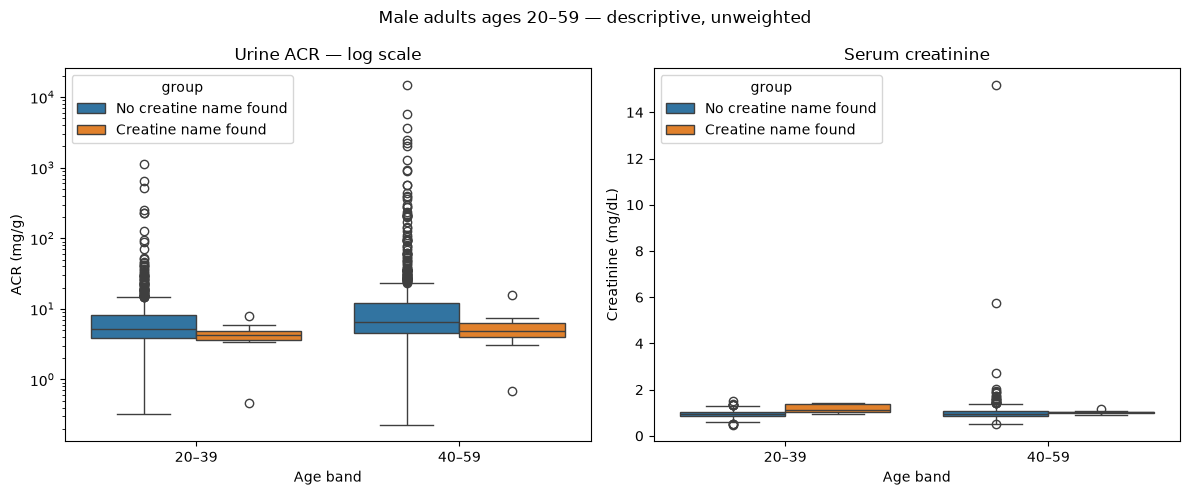

Saved figure to: ../figures/phase1_kidney_by_age_sex.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plot_data = men[men["age_band"].isin(["20–39", "40–59"])].copy()
plot_data = plot_data[plot_data["URDACT"] > 0]

plot_data["group"] = plot_data["broad_creatine"].map({
    True: "Creatine name found",
    False: "No creatine name found",
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=plot_data,
    x="age_band",
    y="URDACT",
    hue="group",
    ax=axes[0],
    order=["20–39", "40–59"],
)
axes[0].set_yscale("log")
axes[0].set_title("Urine ACR — log scale")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("ACR (mg/g)")

sns.boxplot(
    data=plot_data,
    x="age_band",
    y="LBXSCR",
    hue="group",
    ax=axes[1],
    order=["20–39", "40–59"],
)
axes[1].set_title("Serum creatinine")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Creatinine (mg/dL)")

fig.suptitle("Male adults ages 20–59 — descriptive, unweighted")
fig.tight_layout()

output_path = Path("../figures/phase1_kidney_by_age_sex.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {output_path}")